In [4]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Network-Protocol-Classification"

DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")
OUTPUT_PATH = os.path.join(PROJECT_PATH, "outputs")
GRAPH_PATH = os.path.join(OUTPUT_PATH, "graphs")
REPORT_PATH = os.path.join(PROJECT_PATH, "reports")
SCREENSHOT_PATH = os.path.join(PROJECT_PATH, "screenshots")

print("PROJECT DIRECTORY:", os.listdir(PROJECT_PATH))

print("\nDATASET FILES:")
print(os.listdir(DATASET_PATH))

PROJECT DIRECTORY: ['dataset', 'outputs', 'screenshots', 'reports']

DATASET FILES:
['KT_GameBox_3.csv', 'KT_GameBox_2.csv', 'KT_GameBox_5.csv', 'KT_GameBox_9.csv', 'KT_GameBox_8.csv', 'KT_GameBox_4.csv', 'KT_GameBox_6.csv', 'KT_GameBox_7.csv', 'KT_GameBox_1.csv', 'KT_GameBox_10.csv']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATASET_FILE = DATASET_PATH + "/KT_GameBox_3.csv"

df = pd.read_csv(DATASET_FILE, nrows=100000)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (100000, 7)


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-02 18:55:02.765962,10.215.173.1,183.110.235.15,UDP,52,33461 > 45500 Len=24
1,2,2022-10-02 18:55:02.778164,10.215.173.1,183.110.235.15,UDP,52,33461 > 45500 Len=24
2,3,2022-10-02 18:55:03.766212,192.0.0.2,10.215.173.2,TCP,60,48852 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
3,4,2022-10-02 18:55:04.595782,10.215.173.1,10.215.173.2,DNS,68,Standard query 0x0d16 A gbc.play.ktgamebox.com
4,5,2022-10-02 18:55:04.675534,10.215.173.1,10.215.173.2,DNS,68,Standard query 0x3da6 A gba.play.ktgamebox.com


In [5]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATASET INFORMATION:")
df.info()

print("\nSTATISTICAL SUMMARY:")
display(df.describe())

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

COLUMN NAMES:
['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   No.          100000 non-null  int64 
 1   Time         100000 non-null  object
 2   Source       100000 non-null  object
 3   Destination  100000 non-null  object
 4   Protocol     100000 non-null  object
 5   Length       100000 non-null  int64 
 6   Info         100000 non-null  object
dtypes: int64(2), object(5)
memory usage: 5.3+ MB

STATISTICAL SUMMARY:


,No.,Length
count,100000.000000,100000.000000
mean,50000.500000,1109.553340
std,28867.657797,439.665431
min,1.000000,32.000000
25%,25000.750000,1300.000000
50%,50000.500000,1300.000000
75%,75000.250000,1300.000000
max,100000.000000,10000.000000



MISSING VALUES:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64

DUPLICATE RECORDS:
0


In [6]:
print("UNIQUE PROTOCOLS:")
print(df["Protocol"].unique())

print("\nPROTOCOL COUNTS:")
print(df["Protocol"].value_counts())

print("\nTOTAL UNIQUE PROTOCOLS:")
print(df["Protocol"].nunique())

UNIQUE PROTOCOLS:
['UDP' 'TCP' 'DNS' 'TLSv1.3' 'TLSv1' 'TLSv1.2']

PROTOCOL COUNTS:
Protocol
UDP        92749
TCP         7113
TLSv1         78
TLSv1.3       38
TLSv1.2       12
DNS           10
Name: count, dtype: int64

TOTAL UNIQUE PROTOCOLS:
6


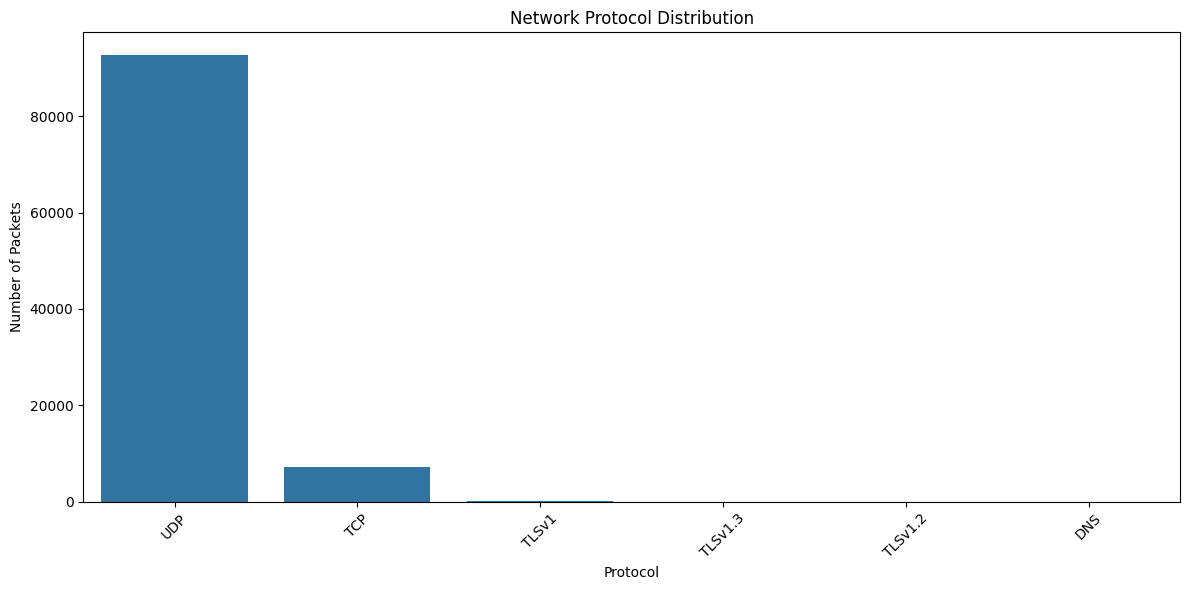

In [7]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.title("Network Protocol Distribution")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

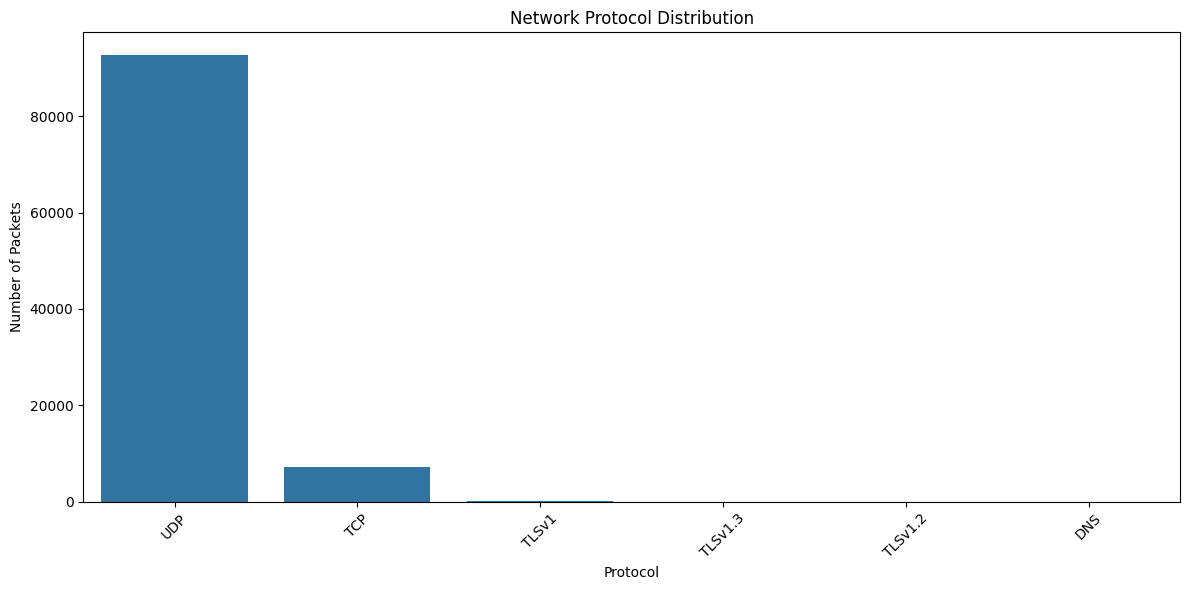

In [8]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.title("Network Protocol Distribution")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    GRAPH_PATH + "/protocol_distribution.png",
    dpi=300
)

plt.show()

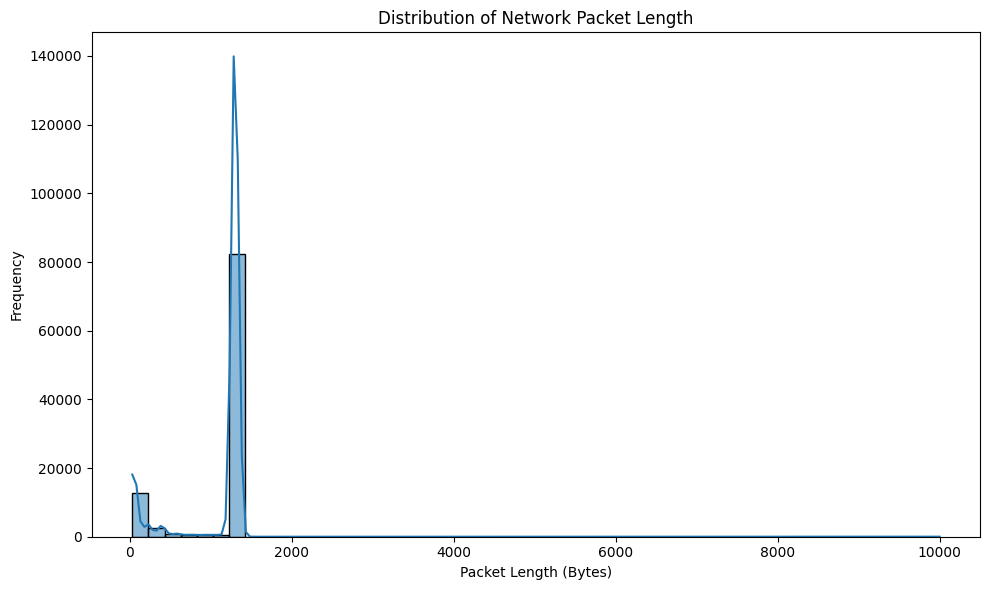

In [9]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Length",
    bins=50,
    kde=True
)

plt.title("Distribution of Network Packet Length")
plt.xlabel("Packet Length (Bytes)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    GRAPH_PATH + "/packet_length_distribution.png",
    dpi=300
)

plt.show()

In [10]:
df["Time"] = pd.to_datetime(
    df["Time"],
    errors="coerce"
)

df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

print("Time features created successfully!")

display(df[["Time", "Hour", "Minute", "Second"]].head())

Time features created successfully!


,Time,Hour,Minute,Second
0,2022-10-02 18:55:02.765962,18,55,2
1,2022-10-02 18:55:02.778164,18,55,2
2,2022-10-02 18:55:03.766212,18,55,3
3,2022-10-02 18:55:04.595782,18,55,4
4,2022-10-02 18:55:04.675534,18,55,4


In [11]:
print("Packet Length Statistics:")
print(df["Length"].describe())

print("\nProtocol-wise Average Packet Length:")
display(
    df.groupby("Protocol")["Length"]
      .agg(["count", "mean", "min", "max"])
      .sort_values("count", ascending=False)
)

Packet Length Statistics:
count    100000.000000
mean       1109.553340
std         439.665431
min          32.000000
25%        1300.000000
50%        1300.000000
75%        1300.000000
max       10000.000000
Name: Length, dtype: float64

Protocol-wise Average Packet Length:


,count,mean,min,max
Protocol,,,,
UDP,92749,1180.779318,32,1300
TCP,7113,187.345705,40,10000
TLSv1,78,204.243590,146,1700
TLSv1.3,38,717.078947,64,6429
TLSv1.2,12,5143.250000,133,10000
DNS,10,174.400000,67,408


In [12]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Select features and target
X = df[["Length", "Hour", "Minute", "Second"]].copy()
y = df["Protocol"].copy()

# Handle missing feature values
X = X.fillna(0)

# Encode protocol labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Scale features for Logistic Regression and KNN
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Classes:", label_encoder.classes_)
print("Data preparation completed!")

Training data: (80000, 4)
Testing data: (20000, 4)
Classes: ['DNS' 'TCP' 'TLSv1' 'TLSv1.2' 'TLSv1.3' 'UDP']
Data preparation completed!


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = {}

# Train and evaluate models
for name, model in models.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    # Scaled data for Logistic Regression and KNN
    if name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)

    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            labels=range(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

print("\nAll four models trained successfully!")


Logistic Regression
Accuracy: 93.09 %

Classification Report:
              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       0.56      0.23      0.33      1423
       TLSv1       0.00      0.00      0.00        16
     TLSv1.2       0.00      0.00      0.00         2
     TLSv1.3       0.00      0.00      0.00         7
         UDP       0.94      0.99      0.96     18550

    accuracy                           0.93     20000
   macro avg       0.25      0.20      0.22     20000
weighted avg       0.91      0.93      0.92     20000


KNN
Accuracy: 99.16 %

Classification Report:
              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       0.91      0.99      0.95      1423
       TLSv1       0.40      0.12      0.19        16
     TLSv1.2       0.00      0.00      0.00         2
     TLSv1.3       0.60      0.43      0.50         7
         UDP       1.0

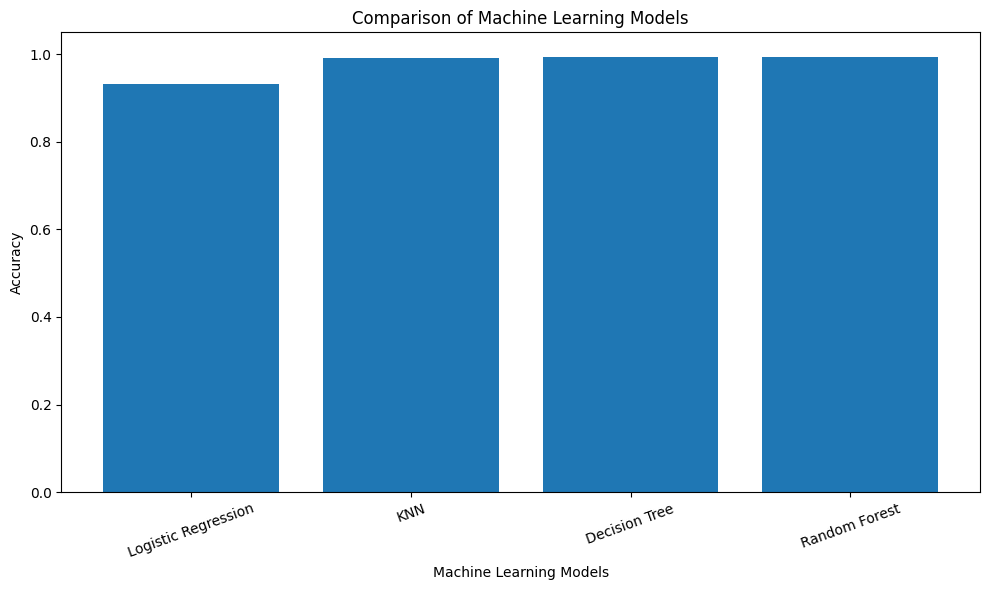

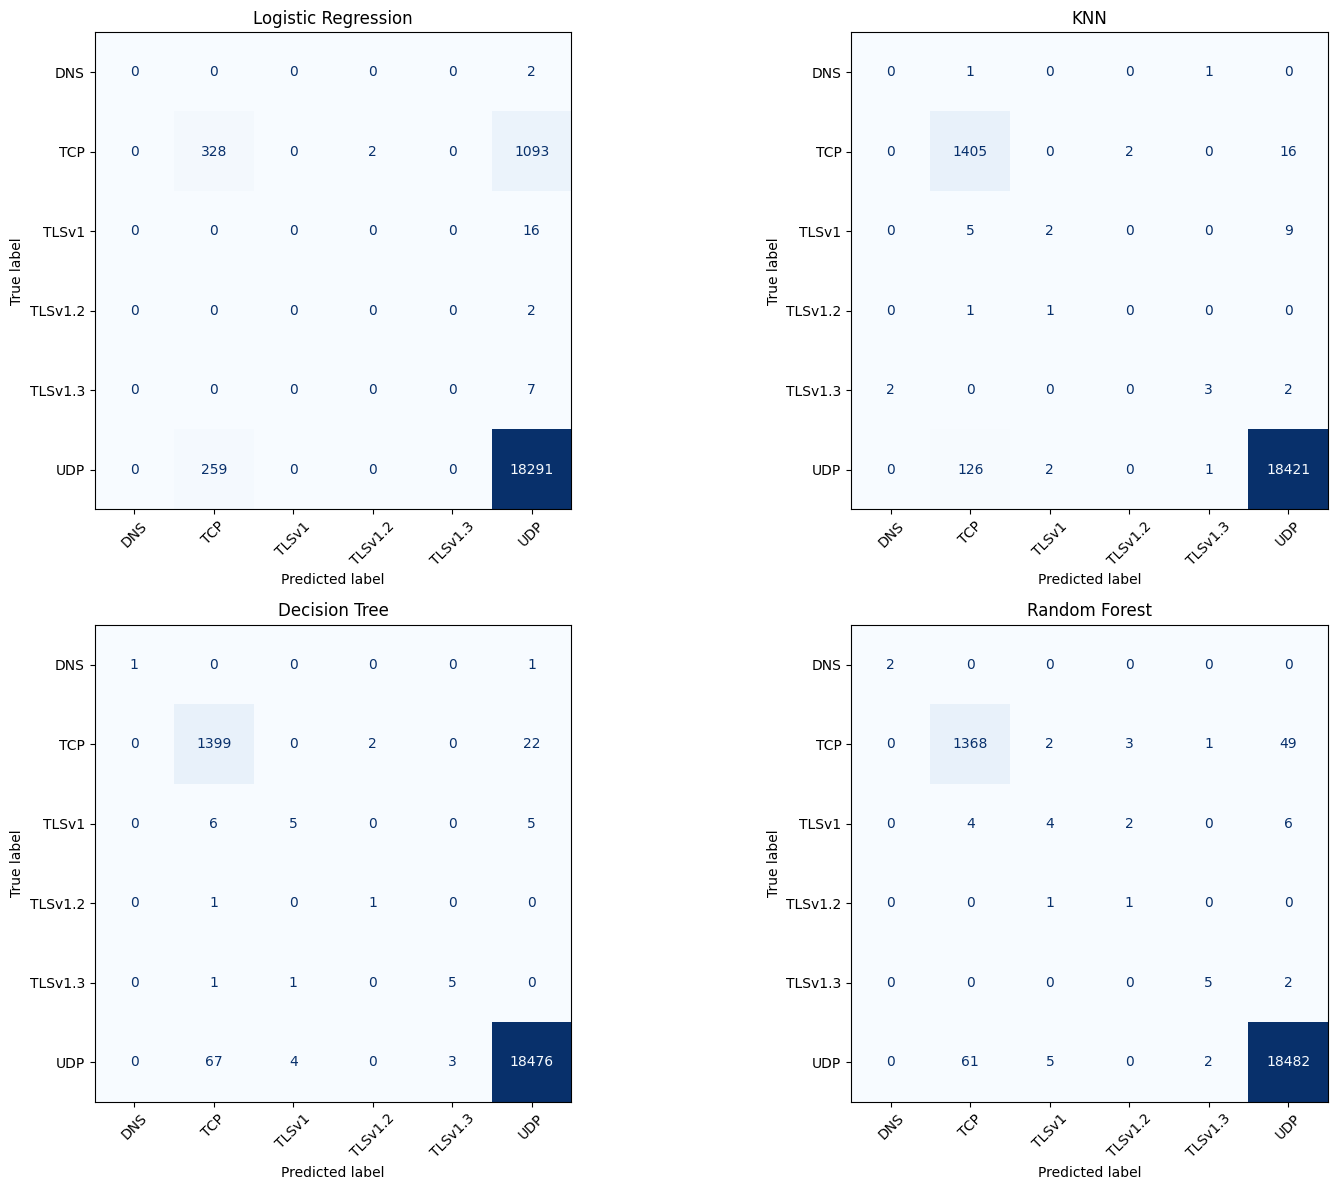

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Model comparison graph
plt.figure(figsize=(10, 6))

plt.bar(results.keys(), results.values())

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig(GRAPH_PATH + "/model_comparison.png", dpi=300)
plt.show()


# Generate predictions and confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for (name, model), ax in zip(models.items(), axes.flatten()):

    if name in ["Logistic Regression", "KNN"]:
        predictions = model.predict(X_test_scaled)
    else:
        predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=range(len(label_encoder.classes_))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )

    display.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(GRAPH_PATH + "/confusion_matrices.png", dpi=300)
plt.show()

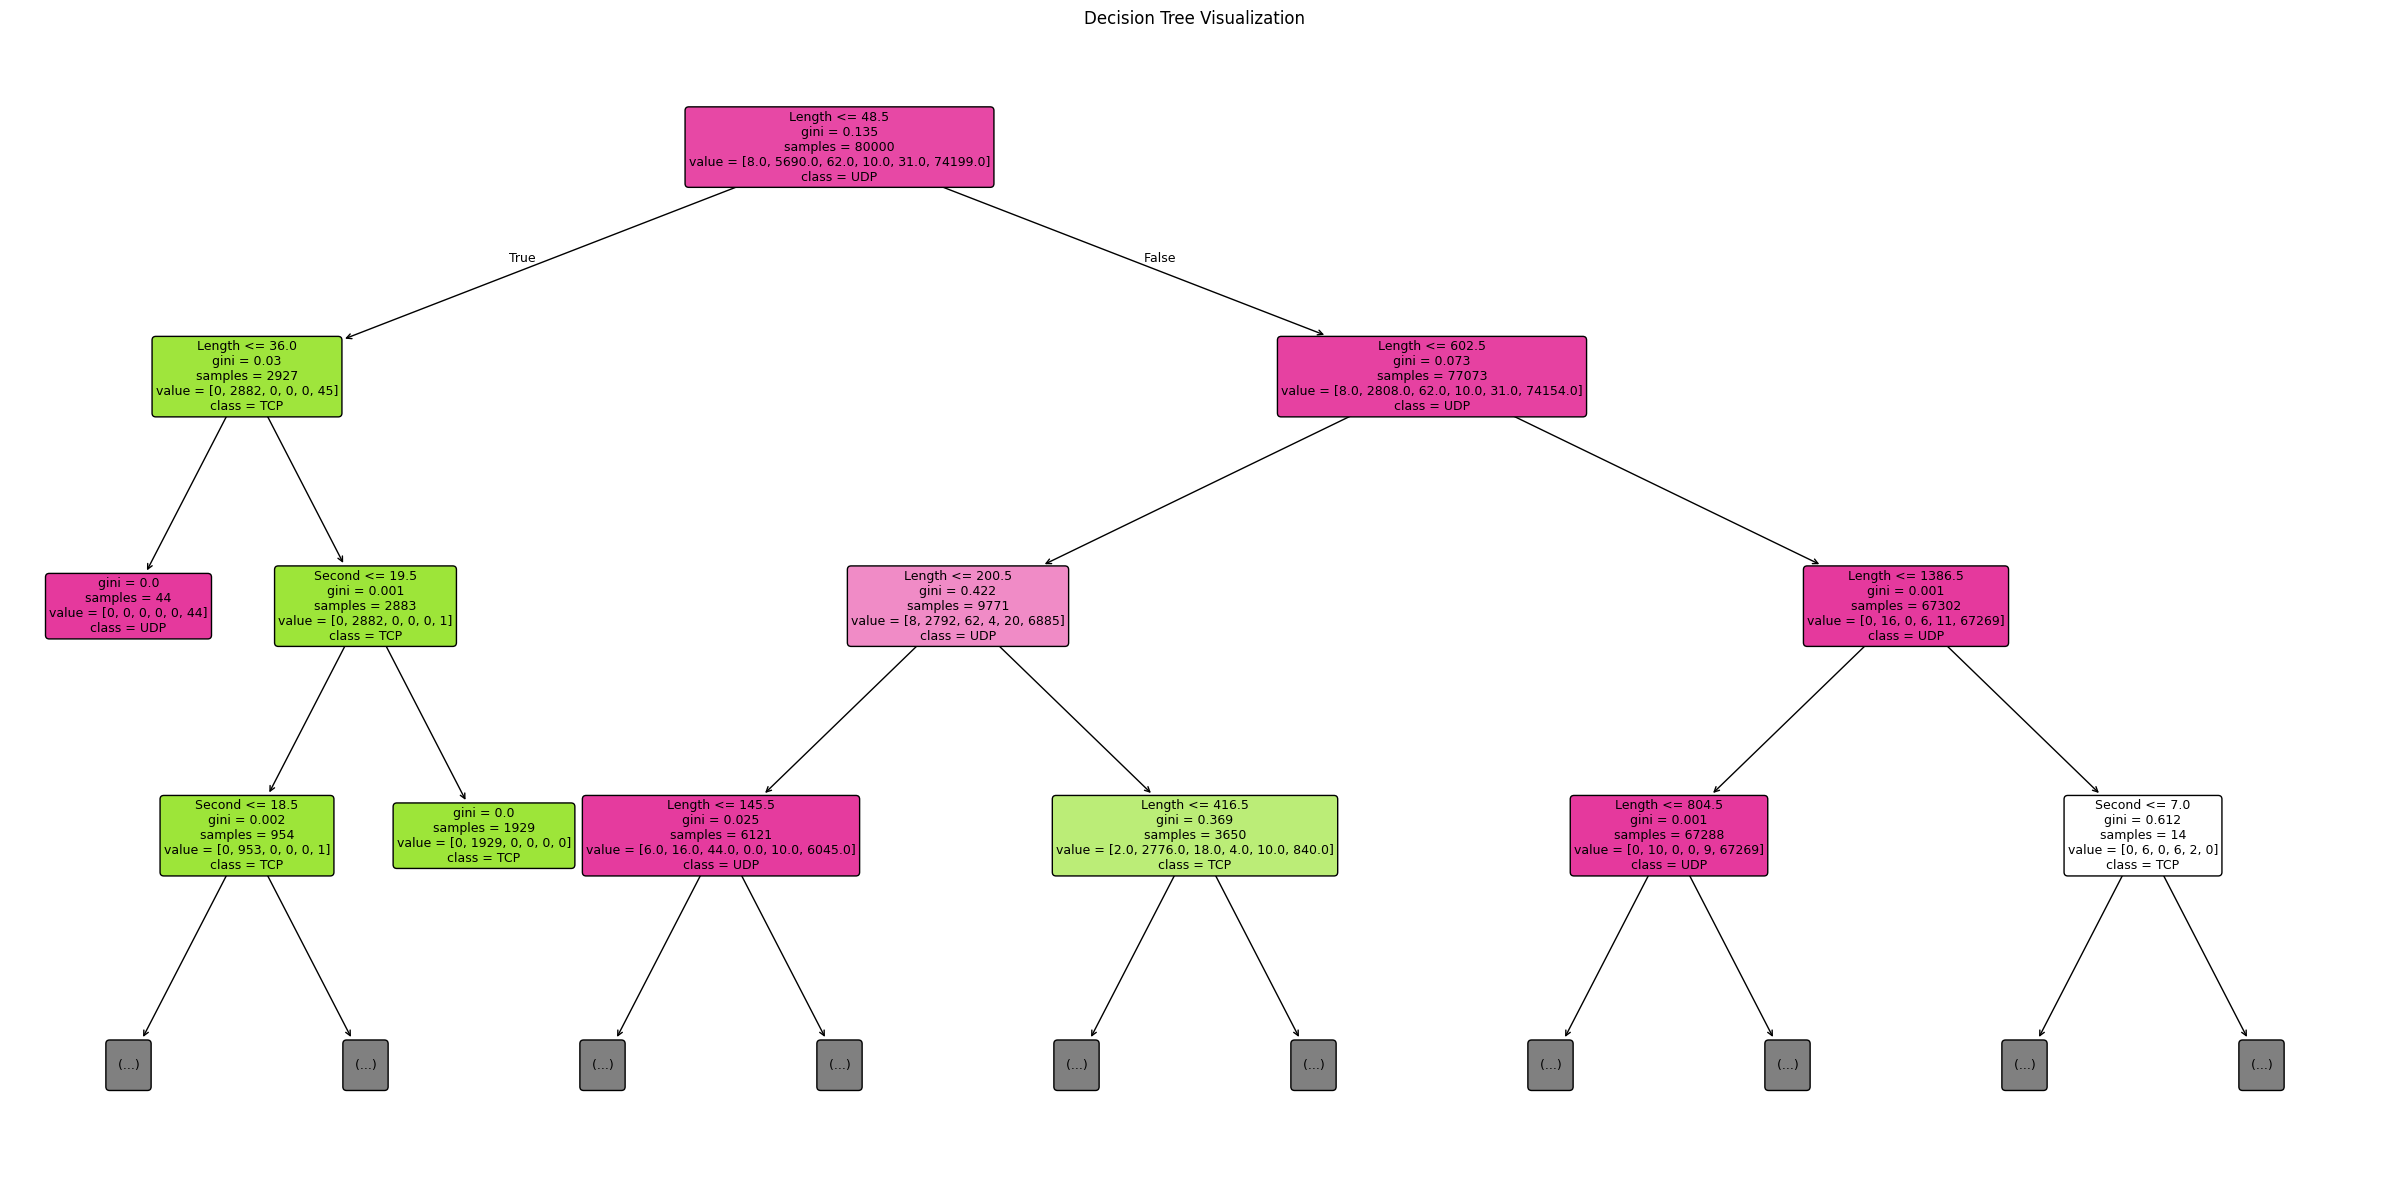

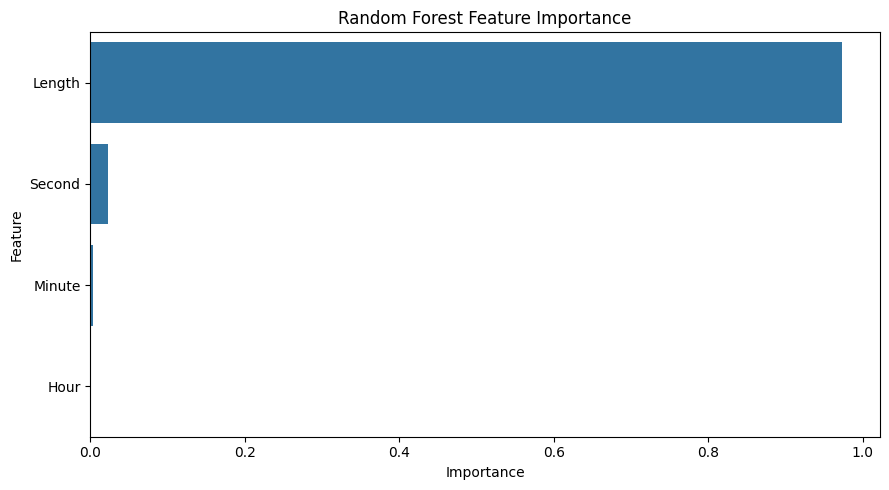

Feature Importance:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [15]:
from sklearn.tree import plot_tree

# 1. Decision Tree Visualization
plt.figure(figsize=(24, 12))

plot_tree(
    models["Decision Tree"],
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization")
plt.tight_layout()

plt.savefig(
    GRAPH_PATH + "/decision_tree.png",
    dpi=300
)

plt.show()


# 2. Random Forest Feature Importance
rf_model = models["Random Forest"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    GRAPH_PATH + "/feature_importance.png",
    dpi=300
)

plt.show()

print("Feature Importance:")
display(importance)


# 3. Predict a New Network Packet
new_packet = pd.DataFrame(
    [[64, 10, 30, 15]],
    columns=["Length", "Hour", "Minute", "Second"]
)

prediction = rf_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(prediction)

print("New Packet Details:")
display(new_packet)

print("Predicted Network Protocol:", predicted_protocol[0])

In [16]:
print("Random Forest Feature Importance:")
print(importance.to_string(index=False))

Random Forest Feature Importance:
Feature  Importance
 Length    0.973719
 Second    0.022535
 Minute    0.003746
   Hour    0.000000


In [17]:
new_packet = pd.DataFrame(
    [[64, 10, 30, 15]],
    columns=["Length", "Hour", "Minute", "Second"]
)

prediction = rf_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(prediction)

print("New Packet Details:")
print(new_packet)

print("\nPredicted Network Protocol:", predicted_protocol[0])

New Packet Details:
   Length  Hour  Minute  Second
0      64    10      30      15

Predicted Network Protocol: UDP


In [18]:
# Save model comparison
comparison = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

comparison.to_csv(
    REPORT_PATH + "/model_comparison.csv",
    index=False
)

# Save feature importance
importance.to_csv(
    REPORT_PATH + "/feature_importance.csv",
    index=False
)

print("Final reports saved successfully!")

Final reports saved successfully!
